In [1]:
%pip install -q numpy pandas matplotlib seaborn plotly scikit-learn ipywidgets

In [2]:
# Imports and reproducible display settings
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

print("Environment ready.")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Environment ready.
NumPy: 2.4.6
Pandas: 3.0.2


In [5]:
# Generate 2,400 synthetic order records over two years
n = 2400
dates = pd.date_range("2024-01-01", "2025-12-31", freq="D")
order_dates = rng.choice(dates, size=n, replace=True)

regions = np.array(["North", "South", "East", "West", "Central"])
channels = np.array(["Online", "Retail", "Partner"])
categories = np.array(["Technology", "Home", "Fashion", "Sports", "Beauty"])

df = pd.DataFrame({
    "order_id": [f"ORD-{i:05d}" for i in range(1, n + 1)],
    "date": pd.to_datetime(order_dates),
    "region": rng.choice(regions, size=n, p=[.23, .20, .18, .22, .17]),
    "channel": rng.choice(channels, size=n, p=[.52, .31, .17]),
    "category": rng.choice(categories, size=n),
    "marketing_spend": rng.gamma(shape=4.0, scale=35.0, size=n),
    "discount_pct": np.clip(rng.normal(12, 7, size=n), 0, 40),
    "customer_satisfaction": np.clip(rng.normal(4.0, .65, size=n), 1, 5),
    "units": rng.integers(1, 9, size=n),
})

# Simulated revenue relationship with seasonality and noise
seasonality = 1 + 0.16 * np.sin(2 * np.pi * pd.to_datetime(df["date"]).dt.dayofyear / 365.25)
region_factor = df["region"].map({"North": 1.10, "South": .94, "East": 1.00, "West": 1.14, "Central": .97})
category_price = df["category"].map({"Technology": 240, "Home": 85, "Fashion": 55, "Sports": 72, "Beauty": 38})
channel_factor = df["channel"].map({"Online": 1.08, "Retail": 1.00, "Partner": .92})
noise = rng.lognormal(mean=0, sigma=.32, size=n)

df["revenue"] = (
    df["units"] * category_price * region_factor * channel_factor * seasonality
    * (1 - df["discount_pct"] / 100) * noise
    + df["marketing_spend"] * rng.uniform(0.3, 1.8, size=n)
).round(2)

# Add a few anomalies and missing values for realistic analysis practice
anomaly_idx = rng.choice(df.index, size=12, replace=False)
df.loc[anomaly_idx, "revenue"] *= rng.uniform(3.5, 7.0, size=len(anomaly_idx))
for col, frac in [("customer_satisfaction", .025), ("marketing_spend", .015), ("discount_pct", .01)]:
    miss_idx = rng.choice(df.index, size=int(n * frac), replace=False)
    df.loc[miss_idx, col] = np.nan

df = df.sort_values("date").reset_index(drop=True)
display(df.head())
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")

,order_id,date,region,channel,category,marketing_spend,discount_pct,customer_satisfaction,units,revenue
0,ORD-02316,2024-01-01,West,Retail,Beauty,105.898569,8.149516,4.172091,3,129.79
1,ORD-02259,2024-01-01,North,Retail,Fashion,127.662574,17.167951,NaN,3,301.44
2,ORD-01488,2024-01-01,West,Online,Technology,90.726393,14.587026,2.591622,4,967.06
3,ORD-01409,2024-01-02,West,Retail,Home,104.400139,6.008813,4.845942,8,1158.11
4,ORD-01949,2024-01-02,Central,Retail,Home,35.312936,21.604120,3.065960,4,331.55


Rows: 2,400 | Columns: 10


In [6]:
print("Data types and non-null counts")
display(df.info())

print("\nMissing values by column")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].rename("missing_count").to_frame())

print(f"\nDuplicate order IDs: {df['order_id'].duplicated().sum()}")
display(df.describe(include="all").T)

analysis_df = df.copy()
numeric_cols = analysis_df.select_dtypes(include=np.number).columns.tolist()
for col in numeric_cols:
    analysis_df[col] = analysis_df[col].fillna(analysis_df[col].median())

analysis_df["month"] = analysis_df["date"].dt.to_period("M").dt.to_timestamp()
analysis_df["year"] = analysis_df["date"].dt.year
analysis_df["weekday"] = analysis_df["date"].dt.day_name()

print("Prepared analysis dataset:", analysis_df.shape)

Data types and non-null counts
<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               2400 non-null   str           
 1   date                   2400 non-null   datetime64[us]
 2   region                 2400 non-null   str           
 3   channel                2400 non-null   str           
 4   category               2400 non-null   str           
 5   marketing_spend        2364 non-null   float64       
 6   discount_pct           2376 non-null   float64       
 7   customer_satisfaction  2340 non-null   float64       
 8   units                  2400 non-null   int64         
 9   revenue                2400 non-null   float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(4)
memory usage: 150.1 KB


None


Missing values by column


,missing_count
customer_satisfaction,60
marketing_spend,36
discount_pct,24



Duplicate order IDs: 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,2400,2400,ORD-02316,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,2400,NaN,NaN,NaN,2024-12-31 09:31:12,2024-01-01 00:00:00,2024-07-01 18:00:00,2024-12-30 00:00:00,2025-07-02 06:00:00,2025-12-31 00:00:00,NaN
region,2400,5,North,560,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel,2400,3,Online,1299,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2400,5,Technology,499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marketing_spend,2364.0,NaN,NaN,NaN,138.662112,12.764915,87.623143,128.065335,176.95099,656.027168,70.627957
discount_pct,2376.0,NaN,NaN,NaN,12.075658,0.0,7.406866,11.900849,16.34101,33.70453,6.688682
customer_satisfaction,2340.0,NaN,NaN,NaN,3.989673,1.982988,3.556238,3.983327,4.451058,5.0,0.613771
units,2400.0,NaN,NaN,NaN,4.4925,1.0,2.0,5.0,7.0,8.0,2.312756
revenue,2400.0,NaN,NaN,NaN,607.816635,50.16,288.72,450.24,704.7625,4977.361677,531.591839


Prepared analysis dataset: (2400, 13)


In [8]:
total_revenue = analysis_df["revenue"].sum()
avg_order_revenue = analysis_df["revenue"].mean()
median_order_revenue = analysis_df["revenue"].median()
avg_satisfaction = analysis_df["customer_satisfaction"].mean()
total_orders = analysis_df["order_id"].nunique()
avg_discount = analysis_df["discount_pct"].mean()

kpis = pd.DataFrame({
    "Metric": ["Total revenue", "Orders", "Mean revenue/order", "Median revenue/order", "Mean satisfaction", "Mean discount"],
    "Value": [
        f"${total_revenue:,.0f}", f"{total_orders:,}", f"${avg_order_revenue:,.2f}",
        f"${median_order_revenue:,.2f}", f"{avg_satisfaction:.2f} / 5", f"{avg_discount:.1f}%"
    ]
})
display(kpis.style.hide(axis="index").set_properties(**{"font-size": "13pt"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
kpi_items = [
    ("Total revenue", total_revenue, "${:,.0f}"),
    ("Orders", total_orders, "{:,.0f}"),
    ("Mean satisfaction", avg_satisfaction, "{:.2f}/5"),
]
for ax, (title, value, fmt) in zip(axes, kpi_items):
    ax.axis("off")
    ax.text(.5, .62, title, ha="center", va="center", fontsize=14, color="#64748b")
    ax.text(.5, .38, fmt.format(value), ha="center", va="center", fontsize=24, weight="bold", color="#0f766e")
    ax.add_patch(plt.Rectangle((.08, .15), .84, .68, fill=False, lw=1.5, ec="#cbd5e1", transform=ax.transAxes))
plt.suptitle("Executive overview · Synthetic order data", fontsize=17, weight="bold")
plt.tight_layout()
plt.show()

<class 'AttributeError'>: The '.style' accessor requires jinja2

In [9]:
total_revenue = analysis_df["revenue"].sum()
avg_order_revenue = analysis_df["revenue"].mean()
median_order_revenue = analysis_df["revenue"].median()
avg_satisfaction = analysis_df["customer_satisfaction"].mean()
total_orders = analysis_df["order_id"].nunique()
avg_discount = analysis_df["discount_pct"].mean()

kpis = pd.DataFrame({
    "Metric": ["Total revenue", "Orders", "Mean revenue/order", "Median revenue/order", "Mean satisfaction", "Mean discount"],
    "Value": [
        f"${total_revenue:,.0f}", f"{total_orders:,}", f"${avg_order_revenue:,.2f}",
        f"${median_order_revenue:,.2f}", f"{avg_satisfaction:.2f} / 5", f"{avg_discount:.1f}%"
    ]
})
display(kpis.style.hide(axis="index").set_properties(**{"font-size": "13pt"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
kpi_items = [
    ("Total revenue", total_revenue, "${:,.0f}"),
    ("Orders", total_orders, "{:,.0f}"),
    ("Mean satisfaction", avg_satisfaction, "{:.2f}/5"),
]
for ax, (title, value, fmt) in zip(axes, kpi_items):
    ax.axis("off")
    ax.text(.5, .62, title, ha="center", va="center", fontsize=14, color="#64748b")
    ax.text(.5, .38, fmt.format(value), ha="center", va="center", fontsize=24, weight="bold", color="#0f766e")
    ax.add_patch(plt.Rectangle((.08, .15), .84, .68, fill=False, lw=1.5, ec="#cbd5e1", transform=ax.transAxes))
plt.suptitle("Executive overview · Synthetic order data", fontsize=17, weight="bold")
plt.tight_layout()
plt.show()

<class 'AttributeError'>: The '.style' accessor requires jinja2

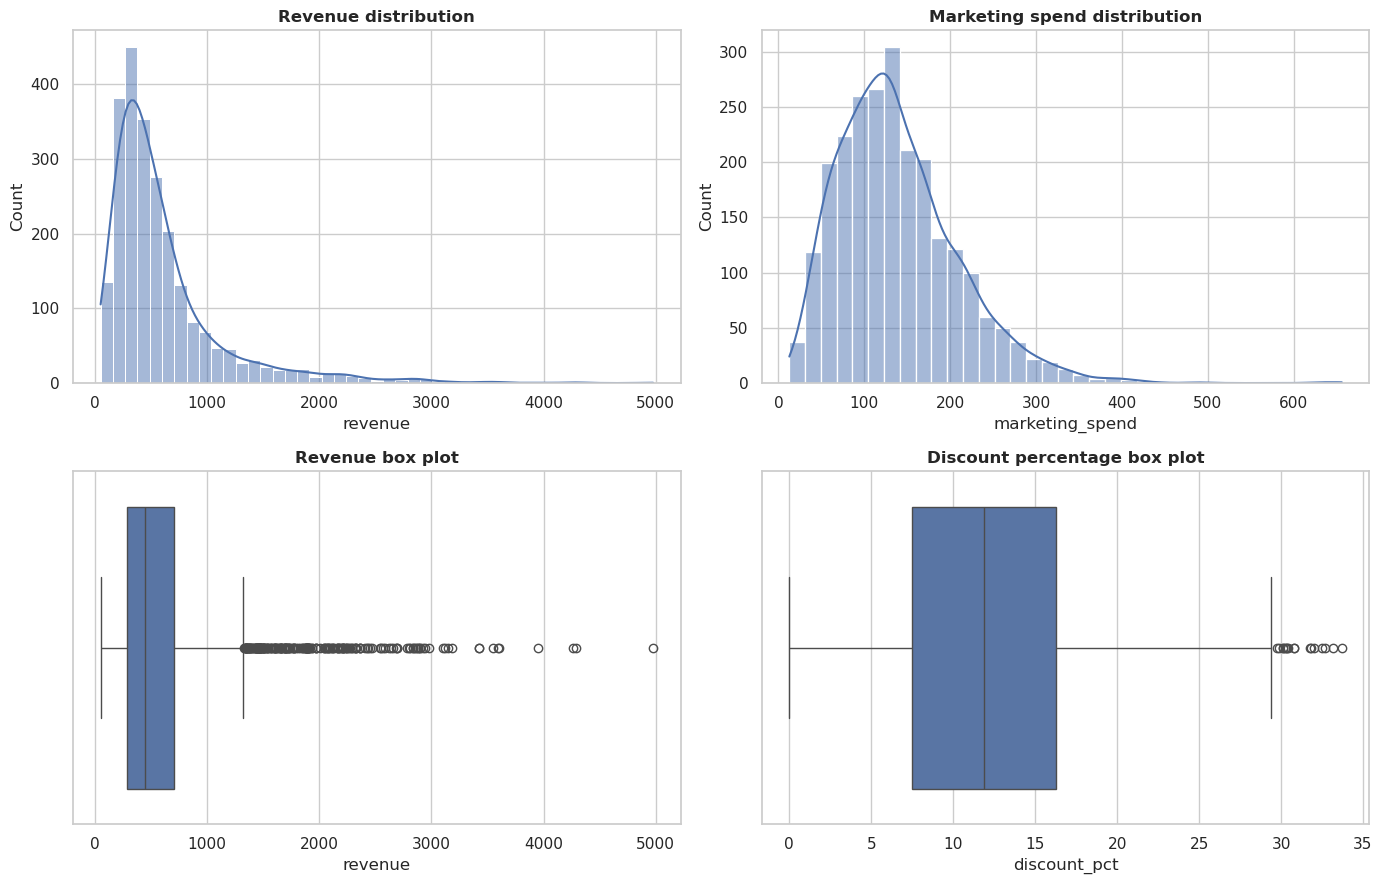

Revenue upper IQR fence: $1,328.83
Orders above the fence: 208 (8.7%)


,order_id,date,region,category,revenue
641,ORD-00744,2024-07-16,North,Technology,4977.361677
1426,ORD-00915,2025-03-08,North,Technology,4293.700000
2194,ORD-01103,2025-11-02,East,Home,4263.589053
2299,ORD-00195,2025-12-02,Central,Technology,3947.590000
1391,ORD-00535,2025-02-26,Central,Technology,3606.110000
864,ORD-00194,2024-09-21,North,Technology,3593.310000
404,ORD-01936,2024-04-29,West,Technology,3547.290000
1269,ORD-00011,2025-01-19,West,Technology,3427.730000
1174,ORD-01492,2024-12-23,South,Technology,3424.870000
586,ORD-00857,2024-06-28,Central,Technology,3180.290000


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(analysis_df["revenue"], bins=45, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Revenue distribution")
sns.histplot(analysis_df["marketing_spend"], bins=35, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Marketing spend distribution")
sns.boxplot(data=analysis_df, x="revenue", ax=axes[1, 0])
axes[1, 0].set_title("Revenue box plot")
sns.boxplot(data=analysis_df, x="discount_pct", ax=axes[1, 1])
axes[1, 1].set_title("Discount percentage box plot")
plt.tight_layout()
plt.show()

q1, q3 = analysis_df["revenue"].quantile([.25, .75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
revenue_outliers = analysis_df.loc[analysis_df["revenue"] > upper_fence, ["order_id", "date", "region", "category", "revenue"]]
print(f"Revenue upper IQR fence: ${upper_fence:,.2f}")
print(f"Orders above the fence: {len(revenue_outliers)} ({len(revenue_outliers)/len(analysis_df):.1%})")
display(revenue_outliers.sort_values("revenue", ascending=False).head(10))

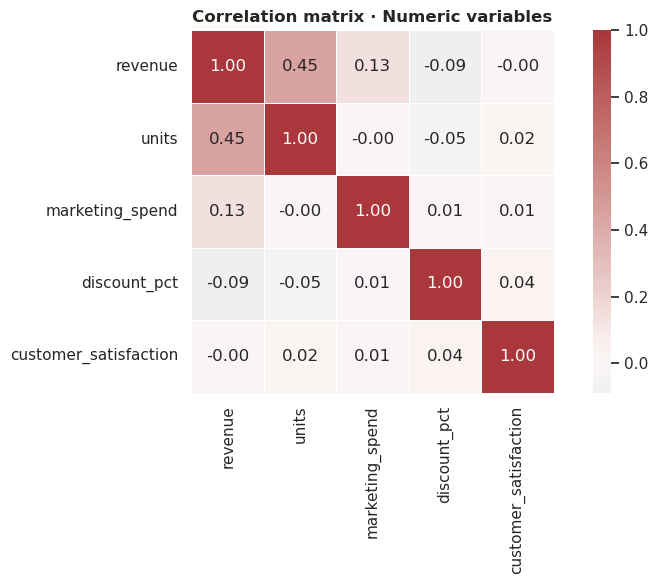

,revenue,units,marketing_spend,discount_pct,customer_satisfaction
revenue,1.000,0.445,0.133,-0.089,-0.002
units,0.445,1.000,-0.004,-0.047,0.020
marketing_spend,0.133,-0.004,1.000,0.009,0.009
discount_pct,-0.089,-0.047,0.009,1.000,0.037
customer_satisfaction,-0.002,0.020,0.009,0.037,1.000


In [11]:
corr_cols = ["revenue", "units", "marketing_spend", "discount_pct", "customer_satisfaction"]
corr = analysis_df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, linewidths=.5)
plt.title("Correlation matrix · Numeric variables")
plt.tight_layout()
plt.show()

display(corr.round(3))

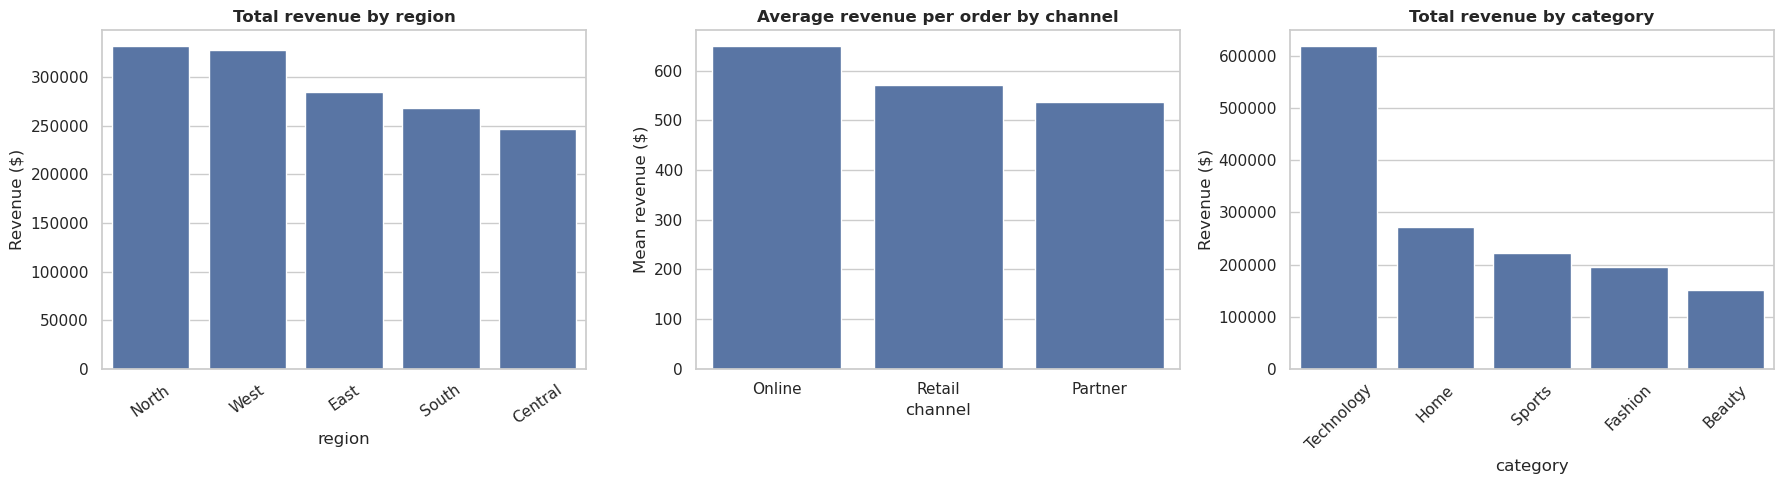

,region,revenue
2,North,331261.06
4,West,327663.75
1,East,284648.22
3,South,268239.79
0,Central,246947.11


,channel,revenue
0,Online,648.47
2,Retail,571.47
1,Partner,536.71


,category,revenue
4,Technology,617688.41
2,Home,271302.05
3,Sports,222283.80
1,Fashion,195692.81
0,Beauty,151792.87


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

region_rev = analysis_df.groupby("region", as_index=False)["revenue"].sum().sort_values("revenue", ascending=False)
sns.barplot(data=region_rev, x="region", y="revenue", ax=axes[0])
axes[0].set_title("Total revenue by region")
axes[0].tick_params(axis="x", rotation=35)
axes[0].set_ylabel("Revenue ($)")

channel_avg = analysis_df.groupby("channel", as_index=False)["revenue"].mean().sort_values("revenue", ascending=False)
sns.barplot(data=channel_avg, x="channel", y="revenue", ax=axes[1])
axes[1].set_title("Average revenue per order by channel")
axes[1].set_ylabel("Mean revenue ($)")

category_rev = analysis_df.groupby("category", as_index=False)["revenue"].sum().sort_values("revenue", ascending=False)
sns.barplot(data=category_rev, x="category", y="revenue", ax=axes[2])
axes[2].set_title("Total revenue by category")
axes[2].tick_params(axis="x", rotation=45)
axes[2].set_ylabel("Revenue ($)")

plt.tight_layout()
plt.show()

display(region_rev.assign(revenue=region_rev["revenue"].round(2)))
display(channel_avg.assign(revenue=channel_avg["revenue"].round(2)))
display(category_rev.assign(revenue=category_rev["revenue"].round(2)))

In [13]:
from ipywidgets import interact, Dropdown

def interactive_segment_view(region="All", category="All", channel="All"):
    view = analysis_df.copy()
    if region != "All":
        view = view[view["region"] == region]
    if category != "All":
        view = view[view["category"] == category]
    if channel != "All":
        view = view[view["channel"] == channel]

    if view.empty:
        print("No records match these filters.")
        return

    monthly = view.groupby("month", as_index=False).agg(revenue=("revenue", "sum"), orders=("order_id", "nunique"))
    fig = px.line(monthly, x="month", y="revenue", markers=True,
                  title=f"Monthly revenue · {len(view):,} matching orders",
                  labels={"month": "Month", "revenue": "Revenue ($)"})
    fig.update_layout(template="plotly_white", hovermode="x unified")
    fig.show()

    fig2 = px.scatter(view, x="marketing_spend", y="revenue", color="category",
                      size="units", hover_data=["region", "channel", "discount_pct"],
                      title="Marketing spend vs revenue",
                      labels={"marketing_spend": "Marketing spend ($)", "revenue": "Revenue ($)"})
    fig2.update_layout(template="plotly_white")
    fig2.show()

interact(
    interactive_segment_view,
    region=Dropdown(options=["All"] + sorted(analysis_df["region"].unique().tolist()), value="All", description="Region"),
    category=Dropdown(options=["All"] + sorted(analysis_df["category"].unique().tolist()), value="All", description="Category"),
    channel=Dropdown(options=["All"] + sorted(analysis_df["channel"].unique().tolist()), value="All", description="Channel")
);

interactive(children=(Dropdown(description='Region', options=('All', 'Central', 'East', 'North', 'South', 'Wes…

<class 'ValueError'>: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [14]:
monthly = analysis_df.groupby("month", as_index=False).agg(
    revenue=("revenue", "sum"),
    orders=("order_id", "nunique"),
    mean_satisfaction=("customer_satisfaction", "mean")
)
monthly["revenue_3m_avg"] = monthly["revenue"].rolling(3, min_periods=1).mean()

fig = go.Figure()
fig.add_trace(go.Bar(x=monthly["month"], y=monthly["revenue"], name="Monthly revenue", opacity=.55))
fig.add_trace(go.Scatter(x=monthly["month"], y=monthly["revenue_3m_avg"], name="3-month rolling average", mode="lines"))
fig.update_layout(title="Monthly revenue and rolling average", xaxis_title="Month", yaxis_title="Revenue ($)",
                  template="plotly_white", hovermode="x unified")
fig.show()

fig = px.line(monthly, x="month", y="orders", markers=True, title="Monthly order count",
              labels={"month": "Month", "orders": "Orders"})
fig.update_layout(template="plotly_white")
fig.show()

display(monthly.tail(12).round(2))

<class 'ValueError'>: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [16]:
anomaly_features = ["revenue", "units", "marketing_spend", "discount_pct", "customer_satisfaction"]
X_anomaly = analysis_df[anomaly_features].copy()

iso = IsolationForest(contamination=0.02, random_state=RANDOM_STATE)
analysis_df["anomaly_flag"] = iso.fit_predict(X_anomaly)
analysis_df["is_anomaly"] = analysis_df["anomaly_flag"] == -1

print(f"Flagged observations: {analysis_df['is_anomaly'].sum()} / {len(analysis_df)} "
      f"({analysis_df['is_anomaly'].mean():.1%})")

fig = px.scatter(
    analysis_df, x="marketing_spend", y="revenue",
    color=analysis_df["is_anomaly"].map({True: "Flagged anomaly", False: "Typical"}),
    hover_data=["order_id", "date", "region", "category"],
    title="Anomaly screening · Marketing spend vs revenue",
    labels={"marketing_spend": "Marketing spend ($)", "revenue": "Revenue ($)", "color": "Observation"}
)
fig.update_layout(template="plotly_white")
fig.show()

display(analysis_df.loc[analysis_df["is_anomaly"],
                        ["order_id", "date", "region", "category", "revenue"]]
        .sort_values("revenue", ascending=False).head(15))

Flagged observations: 48 / 2400 (2.0%)


<class 'ValueError'>: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Holdout MAE : $160.49
Holdout RMSE: $275.87
Holdout R²  : 0.731


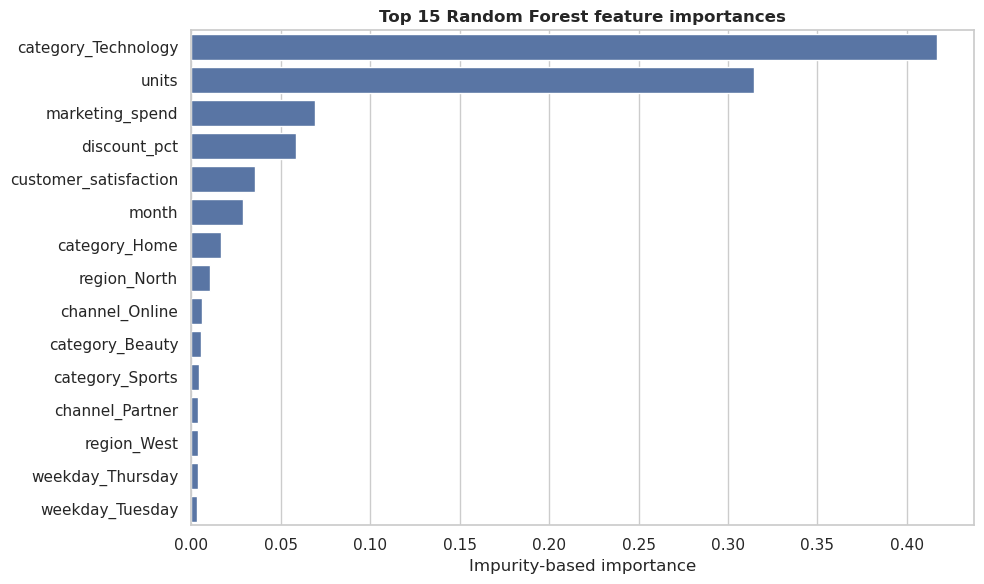

,feature,importance
17,category_Technology,0.416686
3,units,0.314575
0,marketing_spend,0.069192
1,discount_pct,0.058683
2,customer_satisfaction,0.035295
4,month,0.028722
15,category_Home,0.016445
7,region_North,0.010266
10,channel_Online,0.006102
13,category_Beauty,0.005364


In [17]:
model_df = analysis_df.copy()
feature_cols = ["region", "channel", "category", "marketing_spend", "discount_pct",
                "customer_satisfaction", "units", "month", "weekday"]
X = model_df[feature_cols].copy()
y = model_df["revenue"].copy()

X["month"] = X["month"].dt.month
X = pd.get_dummies(X, columns=["region", "channel", "category", "weekday"], drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

model = RandomForestRegressor(
    n_estimators=250, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1
)
model.fit(X_train, y_train)
pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

print(f"Holdout MAE : ${mae:,.2f}")
print(f"Holdout RMSE: ${rmse:,.2f}")
print(f"Holdout R²  : {r2:.3f}")

importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x="importance", y="feature")
plt.title("Top 15 Random Forest feature importances")
plt.xlabel("Impurity-based importance")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(importance)

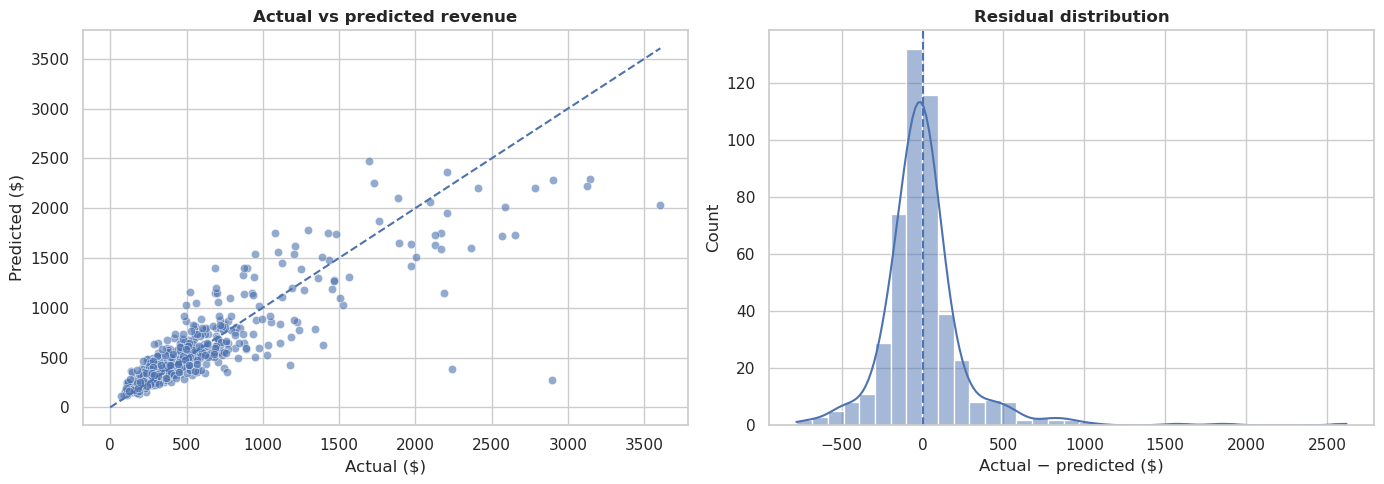

In [18]:
diagnostics = pd.DataFrame({"actual": y_test, "predicted": pred})
diagnostics["residual"] = diagnostics["actual"] - diagnostics["predicted"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=diagnostics, x="actual", y="predicted", alpha=.6, ax=axes[0])
max_val = max(diagnostics["actual"].max(), diagnostics["predicted"].max())
axes[0].plot([0, max_val], [0, max_val], linestyle="--")
axes[0].set_title("Actual vs predicted revenue")
axes[0].set_xlabel("Actual ($)")
axes[0].set_ylabel("Predicted ($)")

sns.histplot(diagnostics["residual"], bins=35, kde=True, ax=axes[1])
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Residual distribution")
axes[1].set_xlabel("Actual − predicted ($)")
plt.tight_layout()
plt.show()

In [19]:
best_region = region_rev.iloc[0]
best_category = category_rev.iloc[0]
best_channel = channel_avg.iloc[0]
worst_channel = channel_avg.iloc[-1]
peak_month = monthly.loc[monthly["revenue"].idxmax()]
low_month = monthly.loc[monthly["revenue"].idxmin()]

insights = [
    f"**Revenue leader by region:** {best_region['region']} with ${best_region['revenue']:,.0f} in total revenue.",
    f"**Largest category by total revenue:** {best_category['category']} with ${best_category['revenue']:,.0f}.",
    f"**Highest average order revenue by channel:** {best_channel['channel']} (${best_channel['revenue']:,.2f} per order).",
    f"**Lowest average order revenue by channel:** {worst_channel['channel']} (${worst_channel['revenue']:,.2f} per order).",
    f"**Highest-revenue month:** {peak_month['month']:%B %Y} (${peak_month['revenue']:,.0f}).",
    f"**Lowest-revenue month:** {low_month['month']:%B %Y} (${low_month['revenue']:,.0f}).",
    f"**Anomaly screening:** {analysis_df['is_anomaly'].sum()} observations were flagged ({analysis_df['is_anomaly'].mean():.1%}).",
    f"**Model test performance:** MAE ${mae:,.2f}; RMSE ${rmse:,.2f}; R² {r2:.3f}."
]
display(Markdown("\n".join(f"- {item}" for item in insights)))

- **Revenue leader by region:** North with $331,261 in total revenue.
- **Largest category by total revenue:** Technology with $617,688.
- **Highest average order revenue by channel:** Online ($648.47 per order).
- **Lowest average order revenue by channel:** Partner ($536.71 per order).
- **Highest-revenue month:** April 2024 ($76,977).
- **Lowest-revenue month:** September 2024 ($47,064).
- **Anomaly screening:** 48 observations were flagged (2.0%).
- **Model test performance:** MAE $160.49; RMSE $275.87; R² 0.731.

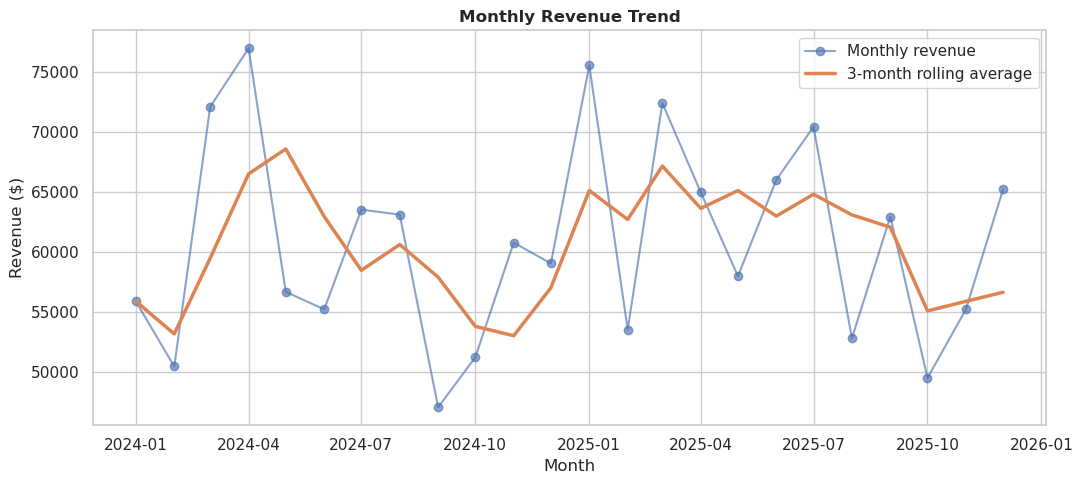

Exports created:
 • data_science_dashboard_orders.csv
 • monthly_revenue_summary.csv
 • random_forest_feature_importance.csv
 • model_test_diagnostics.csv
 • monthly_revenue_trend.png


In [20]:
# Export prepared data and analytical outputs
analysis_df.to_csv("data_science_dashboard_orders.csv", index=False)
monthly.to_csv("monthly_revenue_summary.csv", index=False)
importance.to_csv("random_forest_feature_importance.csv", index=False)
diagnostics.to_csv("model_test_diagnostics.csv", index=False)

# Save a high-resolution static chart
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly["month"], monthly["revenue"], marker="o", alpha=.65, label="Monthly revenue")
ax.plot(monthly["month"], monthly["revenue_3m_avg"], linewidth=2.5, label="3-month rolling average")
ax.set_title("Monthly Revenue Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue ($)")
ax.legend()
fig.tight_layout()
fig.savefig("monthly_revenue_trend.png", dpi=180, bbox_inches="tight")
plt.show()

print("Exports created:")
for filename in [
    "data_science_dashboard_orders.csv",
    "monthly_revenue_summary.csv",
    "random_forest_feature_importance.csv",
    "model_test_diagnostics.csv",
    "monthly_revenue_trend.png",
]:
    print(" •", filename)